In [1]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = make_moons(n_samples=500, noise=0.2, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

for opt in ['sgd', 'rmsprop', 'adam']:

    model = Sequential([
        Dense(16, activation='relu', input_shape=(2,)),
        Dense(8, activation='relu'),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=opt,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        X_train, y_train, epochs=50, verbose=0
    )

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    print("\nOptimizer:", opt)
    print("Final Training Loss:", history.history['loss'][-1])
    print("Testing Loss:", loss)
    print("Testing Accuracy:", accuracy)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Optimizer: sgd
Final Training Loss: 0.2846021354198456
Testing Loss: 0.28677403926849365
Testing Accuracy: 0.8600000143051147

Optimizer: rmsprop
Final Training Loss: 0.2301955372095108
Testing Loss: 0.24657349288463593
Testing Accuracy: 0.8799999952316284

Optimizer: adam
Final Training Loss: 0.2339787632226944
Testing Loss: 0.2348800152540207
Testing Accuracy: 0.8799999952316284


In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

X_train = X_train / 255.0
X_test = X_test / 255.0

model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(256, activation='relu'),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(X_train, y_train, epochs=5, batch_size=32)

loss, accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

pred = model.predict(X_test[:5])
print("Predicted Digits:", pred.argmax(axis=1))
print("Actual Digits:", y_test[:5])

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 8ms/step - accuracy: 0.9379 - loss: 0.2068
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9719 - loss: 0.0878
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9816 - loss: 0.0576
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9858 - loss: 0.0452
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9889 - loss: 0.0330
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9783 - loss: 0.0760
Test Loss: 0.07597089558839798
Test Accuracy: 0.9782999753952026
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
Predicted Digits: [7 2 1 0 4]
Actual Digits: [7 2 1 0 4]


In [3]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = tf.keras.datasets.boston_housing.load_data()[0]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

for dropout in [False, True]:

    layers = [
        Dense(128, activation='relu', input_shape=(X_train.shape[1],))
    ]

    if dropout:
        layers.append(Dropout(0.5))

    layers += [
        Dense(64, activation='relu'),
        Dense(1)
    ]

    model = Sequential(layers)

    model.compile(optimizer='adam', loss='mse', metrics=['mae'])

    model.fit(X_train, y_train, epochs=30, verbose=0)

    loss, mae = model.evaluate(X_test, y_test, verbose=0)

    print("\nDropout:", dropout)
    print("Test Loss:", loss)
    print("Test MAE:", mae)

57026/57026 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Dropout: False
Test Loss: 11.691125869750977
Test MAE: 2.5129308700561523

Dropout: True
Test Loss: 13.197933197021484
Test MAE: 2.7022697925567627


In [4]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.regularizers import l2

X = np.random.rand(500, 5)
y = (X[:, 0] + X[:, 1] > 1).astype(int)

for reg in [None, l2(0.01)]:

    model = Sequential([
        Dense(16, activation='relu',
              kernel_regularizer=reg, input_shape=(5,)),
        Dense(8, activation='relu',
              kernel_regularizer=reg),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    model.fit(X, y, epochs=30, verbose=0)

    print("\nRegularization:", reg)
    print("Accuracy:", model.evaluate(X, y, verbose=0)[1])

    weights = model.layers[0].get_weights()[0]
    print("Average Weight:", np.mean(np.abs(weights)))


Regularization: None
Accuracy: 0.9240000247955322
Average Weight: 0.3390797

Regularization: <keras.src.regularizers.regularizers.L2 object at 0x7d861b8f1400>
Accuracy: 0.9660000205039978
Average Weight: 0.16489938


In [5]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.regularizers import l2
from sklearn.model_selection import train_test_split

X = np.random.rand(1000, 10)
y = (X[:, 0] + X[:, 1] > 1).astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

for reg in [None, l2(0.01)]:

    model = Sequential([
        Dense(64, activation='relu',
              kernel_regularizer=reg, input_shape=(10,)),
        Dense(32, activation='relu',
              kernel_regularizer=reg),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    model.fit(X_train, y_train, epochs=30, verbose=0)

    train_acc = model.evaluate(X_train, y_train, verbose=0)[1]
    test_acc = model.evaluate(X_test, y_test, verbose=0)[1]

    print("\nRegularization:", reg)
    print("Training Accuracy:", train_acc)
    print("Testing Accuracy:", test_acc)


Regularization: None
Training Accuracy: 0.9712499976158142
Testing Accuracy: 0.9549999833106995

Regularization: <keras.src.regularizers.regularizers.L2 object at 0x7d86016a5450>
Training Accuracy: 0.9700000286102295
Testing Accuracy: 0.9800000190734863


In [6]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

X_train = X_train.reshape(-1, 28, 28, 1) / 255.0
X_test = X_test.reshape(-1, 28, 28, 1) / 255.0

model = Sequential([
    Conv2D(32, (3, 3), activation='relu',
           input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(X_train, y_train, epochs=5, batch_size=64)

loss, accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", accuracy)
print("Test Loss:", loss)

pred = model.predict(X_test[:5])
print("Predicted Digits:", pred.argmax(axis=1))
print("Actual Digits:", y_test[:5])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 61s 63ms/step - accuracy: 0.9531 - loss: 0.1559
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 79s 85ms/step - accuracy: 0.9850 - loss: 0.0488
Epoch 3/5
401/938 ━━━━━━━━━━━━━━━━━━━━ 29s 55ms/step - accuracy: 0.9889 - loss: 0.0336

KeyboardInterrupt: 

Input Image:
[[1 2 3 0 1]
 [4 5 6 1 2]
 [7 8 9 2 3]
 [1 2 3 4 5]
 [4 5 6 7 8]]

Convolution Output:
[[  6 -12 -12]
 [  6  -8  -8]
 [  6  -2  -2]]


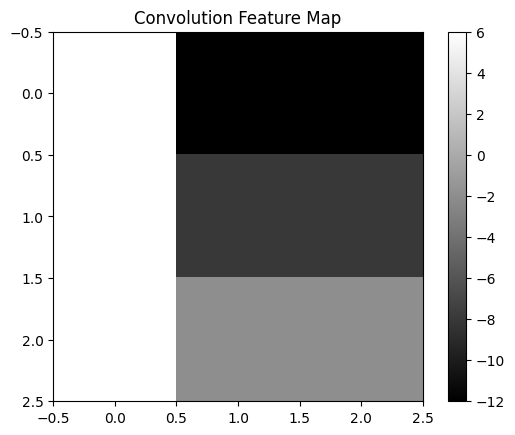

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import convolve2d

image = np.array([
    [1, 2, 3, 0, 1],
    [4, 5, 6, 1, 2],
    [7, 8, 9, 2, 3],
    [1, 2, 3, 4, 5],
    [4, 5, 6, 7, 8]
])

kernel = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
])

conv = convolve2d(image, kernel, mode='valid')

print("Input Image:")
print(image)

print("\nConvolution Output:")
print(conv)

plt.imshow(conv, cmap='gray')
plt.title("Convolution Feature Map")
plt.colorbar()
plt.show()

In [8]:
import numpy as np

image = np.array([
    [1, 2, 3, 4],
    [5, 6, 7, 8],
    [9, 10, 11, 12],
    [13, 14, 15, 16]
])

max_pool = np.zeros((2, 2))
avg_pool = np.zeros((2, 2))

for i in range(2):
    for j in range(2):

        block = image[
            i*2:i*2+2,
            j*2:j*2+2
        ]

        max_pool[i, j] = np.max(block)
        avg_pool[i, j] = np.mean(block)

print("Original Image:")
print(image)

print("\nMax Pooling:")
print(max_pool)

print("\nAverage Pooling:")
print(avg_pool)

Original Image:
[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]
 [13 14 15 16]]

Max Pooling:
[[ 6.  8.]
 [14. 16.]]

Average Pooling:
[[ 3.5  5.5]
 [11.5 13.5]]


In [9]:
!pip install tensorflow-datasets

In [11]:
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Rescaling

# Load cats and dogs dataset
(ds_train, ds_test), info = tfds.load(
    'cats_vs_dogs',
    split=['train[:80%]', 'train[80%:]'],
    as_supervised=True,
    with_info=True
)

def prepare(image, label):
    image = tf.image.resize(image, (128, 128))
    return image, label

train = ds_train.map(prepare).batch(32).prefetch(tf.data.AUTOTUNE)
test = ds_test.map(prepare).batch(32).prefetch(tf.data.AUTOTUNE)

model = Sequential([
    Rescaling(1./255, input_shape=(128, 128, 3)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.fit(train, epochs=5)

loss, accuracy = model.evaluate(test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

ModuleNotFoundError: No module named 'importlib_resources'

In [12]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

X_train = X_train.reshape(-1, 28, 28, 1) / 255.0
X_test = X_test.reshape(-1, 28, 28, 1) / 255.0

for filters, size in [(16, 3), (32, 3), (32, 5), (64, 3)]:

    model = Sequential([
        Conv2D(filters, (size, size), activation='relu',
               input_shape=(28, 28, 1)),
        MaxPooling2D(),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    model.fit(X_train, y_train, epochs=2, verbose=0)

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    print("\nFilters:", filters)
    print("Filter Size:", size)
    print("Accuracy:", accuracy)
    print("Loss:", loss)

KeyboardInterrupt: 

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    RandomRotation, RandomFlip, RandomZoom
)

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

X_train = X_train.reshape(-1, 28, 28, 1) / 255.0
X_test = X_test.reshape(-1, 28, 28, 1) / 255.0

augmentation = Sequential([
    RandomRotation(0.1),
    RandomFlip("horizontal"),
    RandomZoom(0.1)
])

augmented = augmentation(X_train[:5], training=True)

plt.figure(figsize=(10, 4))

for i in range(5):
    plt.subplot(1, 5, i+1)
    plt.imshow(augmented[i].numpy().squeeze(), cmap='gray')
    plt.axis('off')

plt.show()

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense

for use_aug in [False, True]:

    model = Sequential()

    if use_aug:
        model.add(augmentation)

    model.add(Conv2D(32, (3, 3), activation='relu',
                     input_shape=(28, 28, 1)))
    model.add(MaxPooling2D())
    model.add(Flatten())
    model.add(Dense(64, activation='relu'))
    model.add(Dense(10, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    model.fit(X_train, y_train, epochs=3, verbose=0)

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    print("\nAugmentation:", use_aug)
    print("Test Accuracy:", accuracy)

In [13]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense, BatchNormalization
)

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

X_train = X_train.reshape(-1, 28, 28, 1) / 255.0
X_test = X_test.reshape(-1, 28, 28, 1) / 255.0

for use_bn in [False, True]:

    layers = [
        Conv2D(32, (3, 3), activation='relu',
               input_shape=(28, 28, 1))
    ]

    if use_bn:
        layers.append(BatchNormalization())

    layers += [
        MaxPooling2D(),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(10, activation='softmax')
    ]

    model = Sequential(layers)

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    history = model.fit(
        X_train, y_train, epochs=3, verbose=0
    )

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    print("\nBatch Normalization:", use_bn)
    print("Training Loss:", history.history['loss'][-1])
    print("Testing Accuracy:", accuracy)

KeyboardInterrupt: 

In [14]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense

# Daily temperature data
temperature = np.array([
    25, 26, 27, 28, 29,
    30, 29, 28, 27, 26,
    25, 26, 27, 28, 29,
    30, 31, 30, 29, 28,
    27, 26, 27, 28, 29
], dtype=float)

# Normalize data
minimum = temperature.min()
maximum = temperature.max()

data = (temperature - minimum) / (maximum - minimum)

X = []
y = []

for i in range(len(data) - 3):
    X.append(data[i:i+3])
    y.append(data[i+3])

X = np.array(X).reshape(-1, 3, 1)
y = np.array(y)

model = Sequential([
    SimpleRNN(32, activation='tanh', input_shape=(3, 1)),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mse'
)

model.fit(X, y, epochs=100, verbose=0)

prediction = model.predict(X[-1:], verbose=0)

predicted_temp = prediction[0][0] * (maximum - minimum) + minimum

print("Last 3 Days Temperature:", temperature[-3:])
print("Actual Next Temperature:", temperature[-1])
print("Predicted Next Temperature:", round(predicted_temp, 2))
print("Final Loss:", model.evaluate(X, y, verbose=0))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Last 3 Days Temperature: [27. 28. 29.]
Actual Next Temperature: 29.0
Predicted Next Temperature: 29.02
Final Loss: 0.010082541964948177


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D

train = tf.keras.utils.image_dataset_from_directory(
    '/content/plant_dataset/train',
    image_size=(224, 224),
    batch_size=32
)

test = tf.keras.utils.image_dataset_from_directory(
    '/content/plant_dataset/validation',
    image_size=(224, 224),
    batch_size=32
)

base = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base.trainable = False

model = Sequential([
    tf.keras.layers.Lambda(preprocess_input),
    base,
    GlobalAveragePooling2D(),
    Dense(64, activation='relu'),
    Dense(2, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(train, epochs=5)

loss, accuracy = model.evaluate(test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)